# Fitting commuting generators to the CA1 place cells (Fig. 4, App. K)

Fits the exponential map to the rate maps of every spatially tuned CA1 unit of one rat, so
that one model describes one animal's place code, and writes `data/ca1_fit_one_animal_si*.npz`.
The paper's population is the one at 0.5 bits per spike, in `data/ca1_fit_one_animal_si0.50.npz`,
which `fitting_figures` and `fitted_similarity_structure` read.

Three choices define the population (App. K).

1. *One animal.* Rat 25398, which has the most units.
2. *Every spatially tuned unit.* Single-field, multi-field, border-like and unstable units
   alike, with no field criterion. Few units were recorded in any one session, so the
   population is pooled over the rat's sessions and its population vectors were never observed
   simultaneously.
3. *Cross-day repeats removed.* Tetrodes stay in place across days, so the same cell can enter
   the pool once per session. Units on the same tetrode, recorded on different days, whose rate
   maps correlate above `REPEAT_CORRELATION` are treated as one cell, of which the one with
   the highest spatial information is kept.

The fit is run at the paper's information threshold of 0.5 bits per spike and, as a
sensitivity check, at 0.3 and at one standard deviation below the mean of the information
distribution of this rat and of all rats. The fit, the reconstruction scores and the
extrapolation to the part of the arena not trained on are those of `fit_grid_cells`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.sparse.csgraph import connected_components

from expmap.fitting import CommutingGeneratorFit

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT / "notebooks" / "experimental_data"))
from ca1 import load_events, place_fields, population_ratemaps, select_units  # noqa: E402
from galleries import gallery  # noqa: E402

FIGURE_DIR = REPO_ROOT / "figures"
EVENTS = REPO_ROOT / "data" / "ca1_events.npz"
GRID_DATA = REPO_ROOT / "data" / "gc_ratmaps.npy"

# The population.
ANIMAL = "25398"
RATE_RANGE = (1.0, 10.0)  # Hz, mean over the session, the source paper's criterion
INFO_THRESHOLDS = (0.5, 0.3)  # bits per spike; the paper uses 0.5. The two mean - std thresholds are added below.
REPEAT_CORRELATION = 0.9  # same tetrode, different day, rate maps correlated above this: one cell

# Rate maps and field delineation, as in ca1_population.
N_BINS = 32
MAP_SIGMA = 1.0
POSITION_SIGMA = 3.0
SPEED_RANGE = (6.0, 60.0)
FIELD_THRESHOLD = 0.2
FIELD_MIN_BINS = 9

# Fit parameters, as in fit_grid_cells.
N_STEPS = 20000
BATCH_SIZE = 32
MAX_STEP = 2
LR = 1e-3
WAVEVECTOR_LR = 1e-2
ARENA_SIZE = 1.0
SEED = 0

# The extrapolation fit sees the central square of this fraction of the arena side.
FITTED_FRACTION = 0.75


def output_path(threshold):
    return REPO_ROOT / "data" / f"ca1_fit_one_animal_si{threshold:.2f}.npz"

## Population

Rate maps and spatial information for every unit that passes the first two selection steps of
`ca1_population`, nested duplicates dropped and mean rate in range, with no information cut.
The thresholds one standard deviation below the mean are computed from these distributions.

In [2]:
sessions, units = load_events(EVENTS)
rate_passing = select_units(units, RATE_RANGE)
rates_all, _, information_all = population_ratemaps(
    sessions, units, rate_passing, N_BINS, MAP_SIGMA, POSITION_SIGMA, SPEED_RANGE
)
of_animal = np.array([sessions[units[i].session].animal for i in rate_passing]) == ANIMAL

rates, information = rates_all[of_animal], information_all[of_animal]
date = np.array([sessions[units[i].session].date for i in rate_passing[of_animal]])
tetrode = np.array([units[i].tetrode for i in rate_passing[of_animal]])
cluster = np.array([units[i].cluster for i in rate_passing[of_animal]])
n_fields = np.array([place_fields(r, FIELD_THRESHOLD, FIELD_MIN_BINS).max() for r in rates])
del sessions, units, rates_all

thresholds = {f"SI >= {t}": t for t in INFO_THRESHOLDS}
thresholds["mean - std, this rat"] = float(information.mean() - information.std())
thresholds["mean - std, all rats"] = float(information_all.mean() - information_all.std())

print(f"rate-passing units: {len(information_all)} over all rats, {len(information)} of rat {ANIMAL}")
for label, values in [(f"rat {ANIMAL}", information), ("all rats", information_all)]:
    print(
        f"spatial information, {label}: mean {values.mean():.2f}, std {values.std():.2f}, "
        f"median {np.median(values):.2f}, 10/90 pct {np.percentile(values, 10):.2f}/{np.percentile(values, 90):.2f}"
    )

rate-passing units: 425 over all rats, 151 of rat 25398
spatial information, rat 25398: mean 0.98, std 0.76, median 0.87, 10/90 pct 0.04/1.96
spatial information, all rats: mean 0.73, std 0.69, median 0.54, 10/90 pct 0.04/1.69


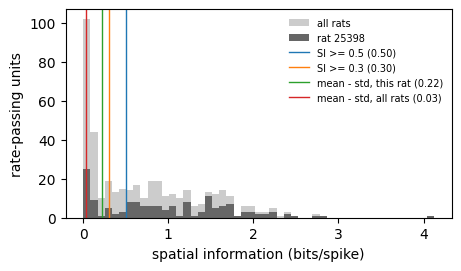

In [3]:
bins = np.linspace(0, max(information_all.max(), information.max()), 50)
fig, ax = plt.subplots(figsize=(4.5, 2.6), layout="constrained")
ax.hist(information_all, bins=bins, color="0.8", label="all rats")
ax.hist(information, bins=bins, color="0.4", label=f"rat {ANIMAL}")
for k, (name, t) in enumerate(thresholds.items()):
    ax.axvline(t, color=f"C{k}", linewidth=1, label=f"{name} ({t:.2f})")
ax.set_xlabel("spatial information (bits/spike)")
ax.set_ylabel("rate-passing units")
ax.legend(frameon=False, fontsize=7)
fig.savefig(FIGURE_DIR / "ca1_one_animal_information.svg", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "ca1_one_animal_information.png", dpi=200, bbox_inches="tight")

## Cross-day repeats

Two units are linked when they sit on the same tetrode, were recorded on different days and
their rate maps correlate above `REPEAT_CORRELATION`. Linked units form a group, and the unit
with the highest spatial information represents it. The rate at which pairs that cannot be the
same cell, on another tetrode or on the same day, exceed the threshold is printed as the
false-positive reference. The groups are shown below.

In [4]:
C = np.corrcoef(rates.reshape(len(rates), -1))
candidate = (tetrode[:, None] == tetrode[None]) & (date[:, None] != date[None])
_, group = connected_components((C > REPEAT_CORRELATION) & candidate, directed=False)

distinct = np.zeros(len(rates), bool)
for g in np.unique(group):
    members = np.flatnonzero(group == g)
    distinct[members[information[members].argmax()]] = True

upper = np.triu(np.ones_like(C, bool), 1)
other = ~candidate & ~np.eye(len(rates), dtype=bool)
print(f"{len(rates)} rate-passing units of rat {ANIMAL}; {distinct.sum()} after removing cross-day repeats")
print(
    f"pairs above r = {REPEAT_CORRELATION}: {(C[candidate & upper] > REPEAT_CORRELATION).sum()} of "
    f"{(candidate & upper).sum()} same-tetrode other-day pairs, "
    f"{(C[other & upper] > REPEAT_CORRELATION).sum()} of {(other & upper).sum()} other pairs"
)

populations = {name: np.flatnonzero(distinct & (information >= t)) for name, t in thresholds.items()}
print(f"\n{'population':24s} threshold  units  (before repeats)  sessions  single-/multi-field/no field")
for name, idx in populations.items():
    t = thresholds[name]
    fields = n_fields[idx]
    print(
        f"{name:24s} {t:9.2f} {len(idx):6d} {(information >= t).sum():17d} {len(set(date[idx])):9d}"
        f"  {(fields == 1).sum()} / {(fields > 1).sum()} / {(fields == 0).sum()}"
    )

151 rate-passing units of rat 25398; 147 after removing cross-day repeats
pairs above r = 0.9: 5 of 2808 same-tetrode other-day pairs, 1 of 8517 other pairs

population               threshold  units  (before repeats)  sessions  single-/multi-field/no field
SI >= 0.5                     0.50    103               107        37  47 / 56 / 0
SI >= 0.3                     0.30    109               113        37  50 / 59 / 0
mean - std, this rat          0.22    112               116        37  51 / 61 / 0
mean - std, all rats          0.03    139               143        40  72 / 67 / 0


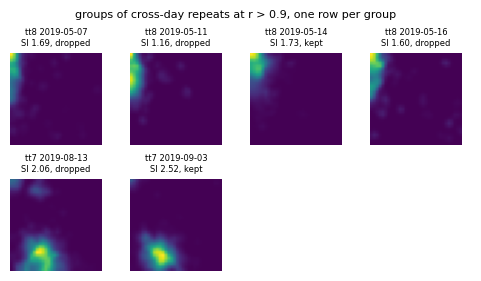

In [5]:
repeated = [np.flatnonzero(group == g) for g in np.unique(group) if (group == g).sum() > 1]
n_cols = max(len(members) for members in repeated)
fig, axs = plt.subplots(
    len(repeated), n_cols, figsize=(n_cols * 1.2, len(repeated) * 1.35), layout="constrained", squeeze=False
)
for ax in axs.ravel():
    ax.axis("off")
for row, members in enumerate(repeated):
    for ax, k in zip(axs[row], members[np.argsort(date[members])]):
        ax.imshow(rates[k].T / rates[k].max(), origin="lower", cmap="viridis", vmin=0, vmax=1)
        kept = "kept" if distinct[k] else "dropped"
        ax.set_title(f"tt{tetrode[k]} {date[k]}\nSI {information[k]:.2f}, {kept}", fontsize=6)
fig.suptitle(f"groups of cross-day repeats at r > {REPEAT_CORRELATION}, one row per group", fontsize=8)
fig.savefig(FIGURE_DIR / "ca1_one_animal_repeats.png", dpi=150, bbox_inches="tight")

## Fit, reconstruction and extrapolation

The same procedure for each population. Maps are scaled by one constant to the maximum of the
grid-cell file. The full-arena fit is scored by the per-unit correlation between data and
model and by the relative rms error. The extrapolation fit sees only the central square and
generates the whole arena from its center. The part not trained on is scored by the per-unit
correlation, with chance as the same statistic over shuffled units, and by the relative rms
error against a flat map at each unit's mean rate in the trained square.

In [6]:
LO = round(N_BINS * (1 - FITTED_FRACTION) / 2)
HI = N_BINS - LO
INNER = np.zeros((N_BINS, N_BINS), bool)
INNER[LO:HI, LO:HI] = True


def relative_error(model, data, mask):
    return float(np.sqrt(((model - data)[:, mask] ** 2).mean()) / np.sqrt((data[:, mask] ** 2).mean()))


def masked_correlation(model, data, mask):
    return np.array([np.corrcoef(g[mask], e[mask])[0, 1] for g, e in zip(model, data)])


def fit_population(experimental):
    """The fit and extrapolation of fit_grid_cells, for rate maps indexed (unit, bins_x, bins_y)."""
    n_units = len(experimental)
    everywhere = np.ones_like(INNER)
    ratemaps = torch.tensor(np.transpose(experimental, (1, 2, 0)))  # (bins_x, bins_y, n_units)

    fit = CommutingGeneratorFit(n_units=n_units, lr=LR, wavevector_lr=WAVEVECTOR_LR, seed=SEED)
    loss_history = fit.fit(
        ratemaps, n_steps=N_STEPS, batch_size=BATCH_SIZE, max_step=MAX_STEP, arena_size=ARENA_SIZE, progress=False
    )
    centre = ratemaps[N_BINS // 2, N_BINS // 2]
    generated = fit.generate(centre, n_bins=N_BINS, extent=1.0, arena_size=ARENA_SIZE).numpy()

    # The crop spans [-FITTED_FRACTION, FITTED_FRACTION] of the arena, so its bins are the arena's bins.
    crop = ratemaps[LO:HI, LO:HI]
    crop_fit = CommutingGeneratorFit(n_units=n_units, lr=LR, wavevector_lr=WAVEVECTOR_LR, seed=SEED)
    crop_loss = crop_fit.fit(
        crop,
        n_steps=N_STEPS,
        batch_size=BATCH_SIZE,
        max_step=MAX_STEP,
        arena_size=FITTED_FRACTION * ARENA_SIZE,
        progress=False,
    )
    crop_centre = crop[(HI - LO) // 2, (HI - LO) // 2]
    extrapolated = crop_fit.generate(crop_centre, n_bins=N_BINS, extent=1.0, arena_size=ARENA_SIZE).numpy()

    peak = np.array([np.unravel_index(m.argmax(), m.shape) for m in experimental])
    flat = np.broadcast_to(experimental[:, INNER].mean(1)[:, None, None], experimental.shape)
    rng = np.random.default_rng(SEED)
    shuffled = [masked_correlation(extrapolated[rng.permutation(n_units)], experimental, ~INNER) for _ in range(20)]
    return {
        "Gx": fit.Gx.detach().numpy(),
        "Gy": fit.Gy.detach().numpy(),
        "R": fit.R.detach().numpy(),
        "wavevectors": fit.wavevectors.detach().numpy(),
        "loss_history": np.array(loss_history),
        "experimental": experimental,
        "generated": generated,
        "correlation": masked_correlation(generated, experimental, everywhere),
        "relative_error": relative_error(generated, experimental, everywhere),
        "inner": INNER,
        "extrapolated": extrapolated,
        "crop_Gx": crop_fit.Gx.detach().numpy(),
        "crop_Gy": crop_fit.Gy.detach().numpy(),
        "crop_loss_history": np.array(crop_loss),
        "field_outside": ~INNER[peak[:, 0], peak[:, 1]],
        "inner_correlation": masked_correlation(extrapolated, experimental, INNER),
        "outer_correlation": masked_correlation(extrapolated, experimental, ~INNER),
        "outer_correlation_chance": float(np.mean([np.nanmedian(s) for s in shuffled])),
        "outer_relative_error": relative_error(extrapolated, experimental, ~INNER),
        "outer_relative_error_flat": relative_error(flat, experimental, ~INNER),
    }


grid_max = float(np.load(GRID_DATA).max())
results = {}
for name, idx in populations.items():
    scale = grid_max / rates[idx].max()
    results[name] = fit_population((rates[idx] * scale).astype("float32")) | {"scale": scale}
    loss = results[name]["loss_history"]
    print(f"{name}: {len(idx)} units, loss {loss[:100].mean():.3e} -> {loss[-100:].mean():.3e}")

SI >= 0.5: 103 units, loss 3.827e-05 -> 2.067e-05


SI >= 0.3: 109 units, loss 3.620e-05 -> 1.979e-05


mean - std, this rat: 112 units, loss 3.568e-05 -> 1.940e-05


mean - std, all rats: 139 units, loss 3.275e-05 -> 1.694e-05


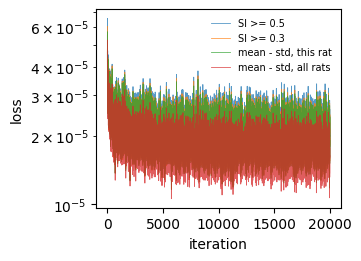

In [7]:
fig, ax = plt.subplots(figsize=(3.5, 2.5), layout="constrained")
for name, r in results.items():
    ax.semilogy(r["loss_history"], linewidth=0.6, alpha=0.75, label=name)
ax.set_xlabel("iteration")
ax.set_ylabel("loss")
ax.legend(frameon=False, fontsize=7)
fig.savefig(FIGURE_DIR / "ca1_one_animal_loss_curves.svg", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "ca1_one_animal_loss_curves.png", dpi=200, bbox_inches="tight")

## Results by threshold

Medians over units with the 10th and 90th percentiles in brackets. "Error" is the relative rms
error, given on the part not trained on next to the flat control.

In [8]:
def spread(values):
    return f"{np.nanmedian(values):.2f} ({np.nanpercentile(values, 10):.2f}/{np.nanpercentile(values, 90):.2f})"


print(f"fitted square: pixels {LO}..{HI} of {N_BINS}\n")
header = "reconstruction corr   error | inside corr | held-out corr      chance   error vs flat | peak in ring"
print(f"{'population':22s} {'SI':>5s} {'N':>4s} | {header}")
for name, r in results.items():
    outside = r["field_outside"]
    print(
        f"{name:22s} {thresholds[name]:5.2f} {len(r['experimental']):4d} | {spread(r['correlation']):20s} "
        f"{r['relative_error']:5.0%} | {np.median(r['inner_correlation']):11.2f} | "
        f"{spread(r['outer_correlation']):18s} {r['outer_correlation_chance']:6.2f}   "
        f"{r['outer_relative_error']:.0%} vs {r['outer_relative_error_flat']:.0%}    | "
        f"{np.nanmedian(r['outer_correlation'][outside]):.2f} ({outside.sum()} units)"
    )

fitted square: pixels 4..28 of 32

population                SI    N | reconstruction corr   error | inside corr | held-out corr      chance   error vs flat | peak in ring
SI >= 0.5               0.50  103 | 0.77 (0.65/0.88)       52% |        0.81 | 0.61 (0.28/0.84)    -0.01   71% vs 92%    | 0.62 (49 units)
SI >= 0.3               0.30  109 | 0.79 (0.64/0.87)       51% |        0.82 | 0.63 (0.27/0.83)    -0.02   69% vs 92%    | 0.64 (51 units)
mean - std, this rat    0.22  112 | 0.80 (0.65/0.89)       50% |        0.83 | 0.62 (0.23/0.85)    -0.01   69% vs 92%    | 0.68 (52 units)
mean - std, all rats    0.03  139 | 0.78 (0.50/0.88)       43% |        0.81 | 0.58 (0.11/0.81)    -0.00   62% vs 77%    | 0.62 (64 units)


### Which units carry the scores

Lowering the threshold adds weakly tuned units. Two questions: how well the added units are
captured, and whether adding them changes how well the strongly tuned ones are captured. Units
are split at 0.5 and 0.3 bits per spike, and by the number of fields.

In [9]:
bands = {"SI >= 0.5": (0.5, np.inf), "0.3 <= SI < 0.5": (0.3, 0.5), "SI < 0.3": (-np.inf, 0.3)}
print(f"{'population':22s} {'band':16s} {'n':>4s}  reconstruction corr  held-out corr")
for name, r in results.items():
    si = information[populations[name]]
    for band, (lo, hi) in bands.items():
        members = (si >= lo) & (si < hi)
        if members.any():
            print(
                f"{name:22s} {band:16s} {members.sum():4d}  {np.median(r['correlation'][members]):19.2f}"
                f"  {np.nanmedian(r['outer_correlation'][members]):13.2f}"
            )

print(f"\n{'population':22s} {'fields':16s} {'n':>4s}  reconstruction corr  held-out corr")
for name, r in results.items():
    fields = n_fields[populations[name]]
    for label, members in [("one", fields == 1), ("two or more", fields > 1), ("none", fields == 0)]:
        if members.any():
            print(
                f"{name:22s} {label:16s} {members.sum():4d}  {np.median(r['correlation'][members]):19.2f}"
                f"  {np.nanmedian(r['outer_correlation'][members]):13.2f}"
            )

population             band                n  reconstruction corr  held-out corr
SI >= 0.5              SI >= 0.5         103                 0.77           0.61
SI >= 0.3              SI >= 0.5         103                 0.80           0.63
SI >= 0.3              0.3 <= SI < 0.5     6                 0.65           0.36
mean - std, this rat   SI >= 0.5         103                 0.81           0.65
mean - std, this rat   0.3 <= SI < 0.5     6                 0.64           0.27
mean - std, this rat   SI < 0.3            3                 0.56           0.32
mean - std, all rats   SI >= 0.5         103                 0.82           0.69
mean - std, all rats   0.3 <= SI < 0.5     6                 0.68           0.36
mean - std, all rats   SI < 0.3           30                 0.51           0.19

population             fields              n  reconstruction corr  held-out corr
SI >= 0.5              one                47                 0.82           0.68
SI >= 0.5              two 

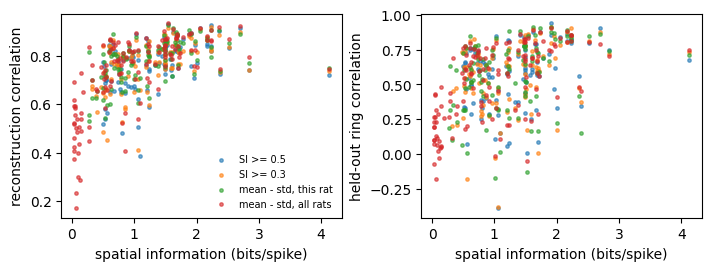

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(7, 2.6), layout="constrained", sharex=True)
for k, (name, r) in enumerate(results.items()):
    si = information[populations[name]]
    axs[0].scatter(si, r["correlation"], s=6, color=f"C{k}", alpha=0.6, label=name)
    axs[1].scatter(si, r["outer_correlation"], s=6, color=f"C{k}", alpha=0.6)
axs[0].set_ylabel("reconstruction correlation")
axs[1].set_ylabel("held-out ring correlation")
for ax in axs:
    ax.set_xlabel("spatial information (bits/spike)")
axs[0].legend(frameon=False, fontsize=7)
fig.savefig(FIGURE_DIR / "ca1_one_animal_scores_by_information.svg", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "ca1_one_animal_scores_by_information.png", dpi=200, bbox_inches="tight")

## Data and model side by side

For each population, units sorted by correlation, best to worst, evenly sampled. Rows alternate
data and model, and each pair shares the unit's own scale.

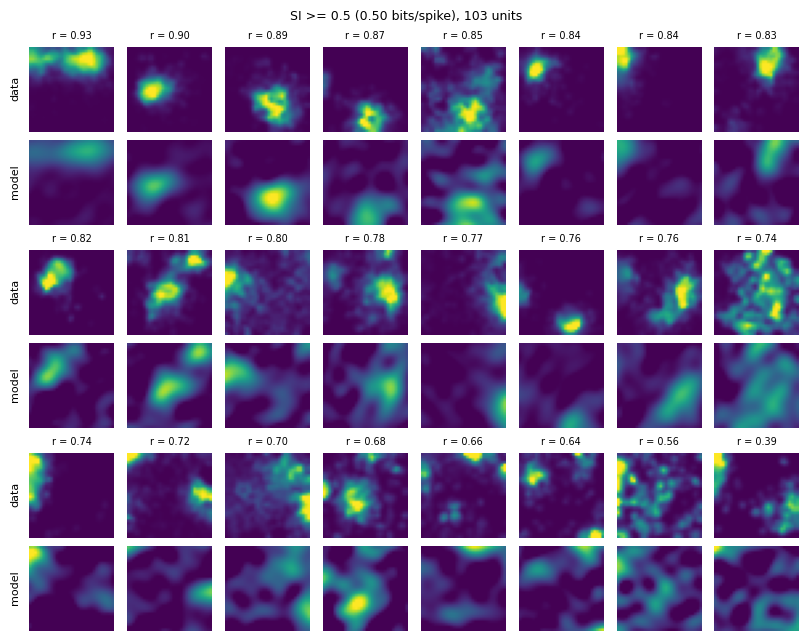

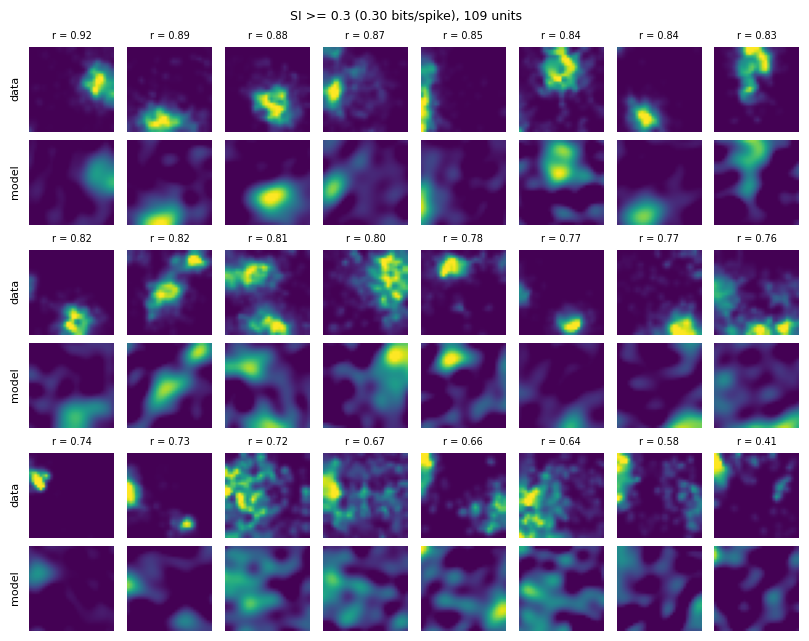

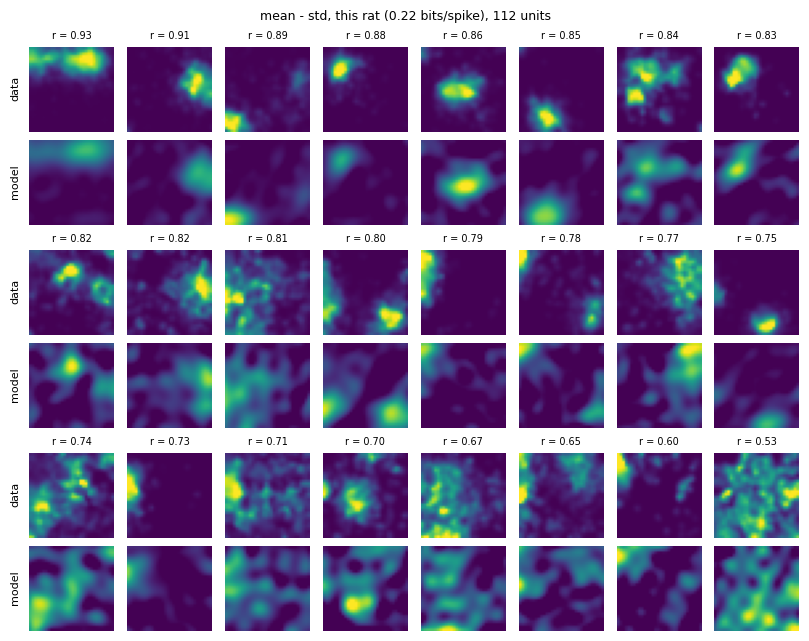

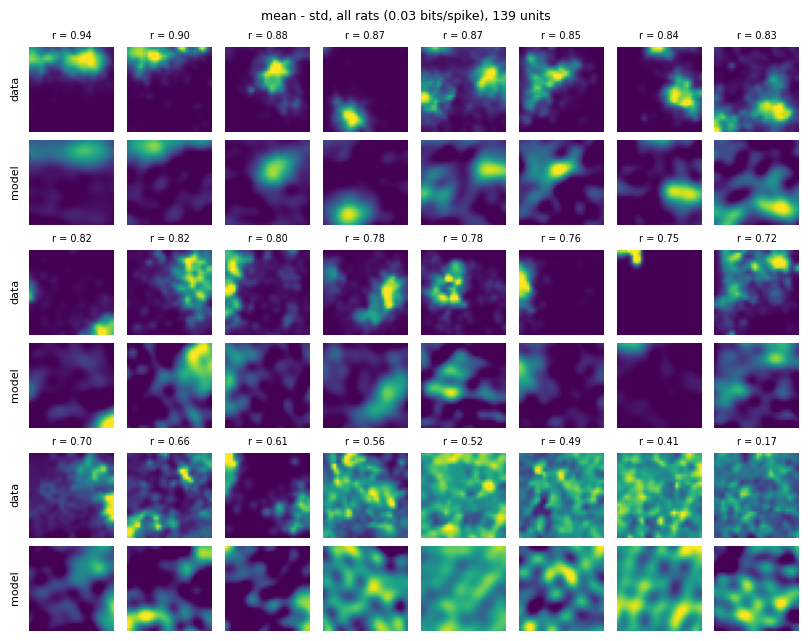

In [11]:
for name, r in results.items():
    fig = gallery(r["experimental"], r["generated"], r["correlation"], n_show=24)
    fig.suptitle(f"{name} ({thresholds[name]:.2f} bits/spike), {len(r['experimental'])} units", fontsize=9)
    fig.savefig(FIGURE_DIR / f"ca1_one_animal_ratemaps_si{thresholds[name]:.2f}.png", dpi=150, bbox_inches="tight")

## The part not trained on

Data above, extrapolation below, the white box is the trained square. All units, sorted by the
correlation over the part not trained on, best to worst, evenly sampled.

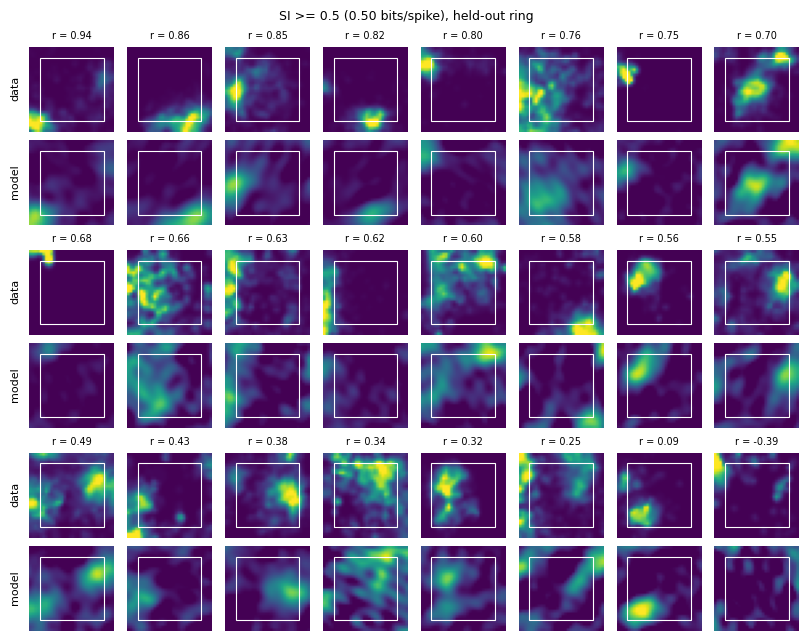

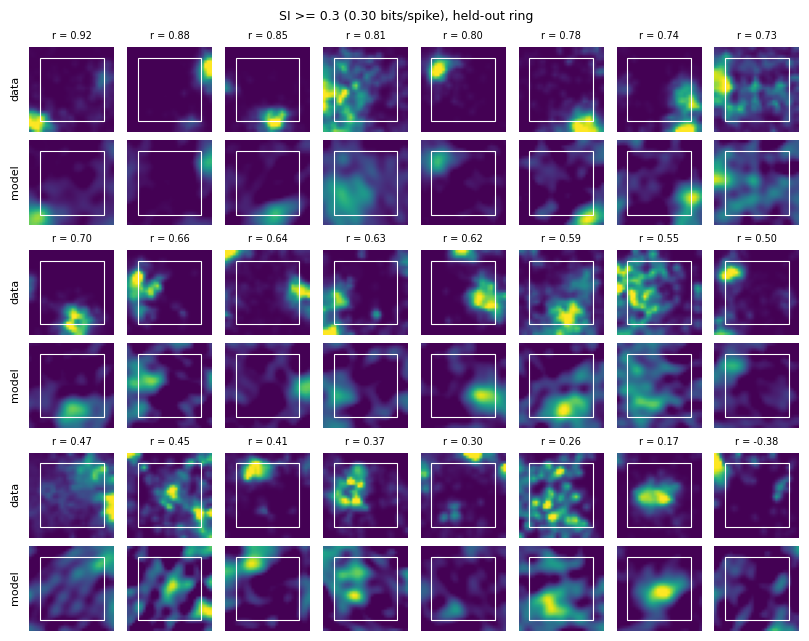

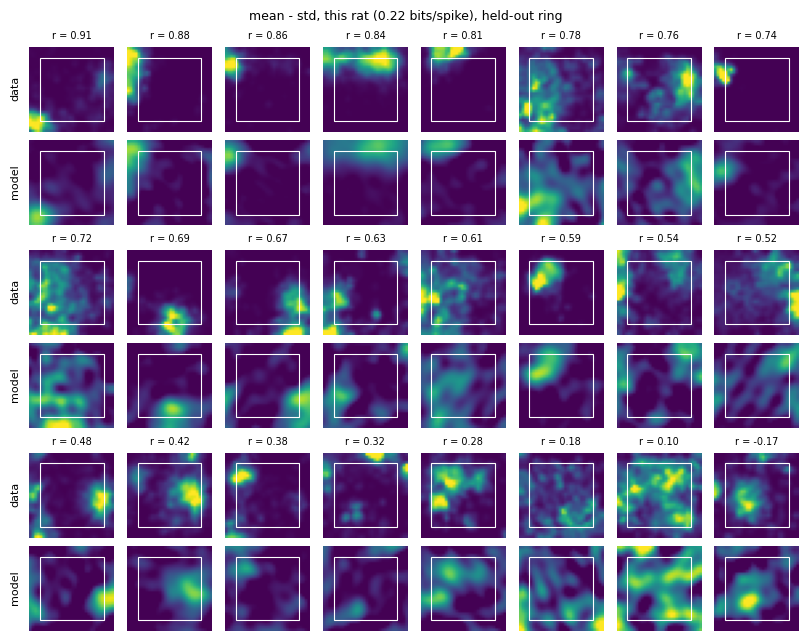

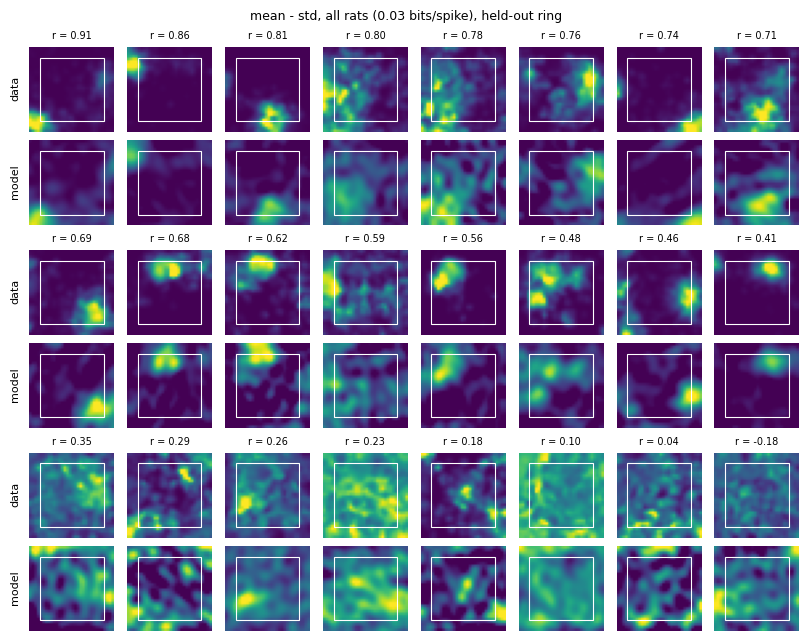

In [12]:
for name, r in results.items():
    fig = gallery(r["experimental"], r["extrapolated"], r["outer_correlation"], box=(LO, HI), n_show=24)
    fig.suptitle(f"{name} ({thresholds[name]:.2f} bits/spike), held-out ring", fontsize=9)
    fig.savefig(FIGURE_DIR / f"ca1_one_animal_extrapolation_si{thresholds[name]:.2f}.png", dpi=150, bbox_inches="tight")

## Save

One file per threshold, in the layout of `data/gc_fit_commuting.npz` with the provenance of
every unit added. Only the file at 0.5 bits per spike is tracked.

In [13]:
for name, r in results.items():
    idx = populations[name]
    np.savez_compressed(
        output_path(thresholds[name]),
        **r,
        seed=SEED,
        n_steps=N_STEPS,
        fitted_fraction=FITTED_FRACTION,
        animal=ANIMAL,
        info_threshold=thresholds[name],
        repeat_correlation=REPEAT_CORRELATION,
        information=information[idx],
        n_fields=n_fields[idx],
        date=date[idx],
        tetrode=tetrode[idx],
        cluster=cluster[idx],
    )
    print(f"saved {output_path(thresholds[name]).name}")

saved ca1_fit_one_animal_si0.50.npz
saved ca1_fit_one_animal_si0.30.npz
saved ca1_fit_one_animal_si0.22.npz
saved ca1_fit_one_animal_si0.03.npz
